
# Assignment 7.2: Clustering Sales Data Using K-Means

**Course:** AIT620 – Methods of Artificial Intelligence and Machine Learning

**Activity 5.01:** Clustering Sales Data Using K-Means

## Introduction

In this assignment, I will use Python and the K-Means clustering algorithm to analyze weekly sales data.

The dataset contains weekly sales information for approximately 800 products over one year.

K-Means is an unsupervised machine learning algorithm that groups similar data points into clusters.

## Objectives

1. Load and explore the weekly sales dataset.
2. Prepare the data for clustering.
3. Apply the K-Means clustering algorithm.
4. Identify an appropriate number of clusters.
5. Visualize and interpret the clustering results.

## Dataset

**Dataset:** Sales Transactions Dataset Weekly

The dataset contains weekly product sales data. Product descriptions and categories are not included.


In [1]:

# Step 3: Load and Explore the Sales Dataset

# Import pandas for data analysis
import pandas as pd

# Load the weekly sales dataset
df = pd.read_csv("Sales_Transactions_Dataset_Weekly.csv")

# Display the dataset dimensions
print("Dataset Shape:", df.shape)

# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display the first five rows
print("\nFirst Five Rows:")
display(df.head())

# Check for missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())


Dataset Shape: (811, 107)

Column Names:
['Product_Code', 'W0', 'W1', 'W2', 'W3', 'W4', 'W5', 'W6', 'W7', 'W8', 'W9', 'W10', 'W11', 'W12', 'W13', 'W14', 'W15', 'W16', 'W17', 'W18', 'W19', 'W20', 'W21', 'W22', 'W23', 'W24', 'W25', 'W26', 'W27', 'W28', 'W29', 'W30', 'W31', 'W32', 'W33', 'W34', 'W35', 'W36', 'W37', 'W38', 'W39', 'W40', 'W41', 'W42', 'W43', 'W44', 'W45', 'W46', 'W47', 'W48', 'W49', 'W50', 'W51', 'MIN', 'MAX', 'Normalized 0', 'Normalized 1', 'Normalized 2', 'Normalized 3', 'Normalized 4', 'Normalized 5', 'Normalized 6', 'Normalized 7', 'Normalized 8', 'Normalized 9', 'Normalized 10', 'Normalized 11', 'Normalized 12', 'Normalized 13', 'Normalized 14', 'Normalized 15', 'Normalized 16', 'Normalized 17', 'Normalized 18', 'Normalized 19', 'Normalized 20', 'Normalized 21', 'Normalized 22', 'Normalized 23', 'Normalized 24', 'Normalized 25', 'Normalized 26', 'Normalized 27', 'Normalized 28', 'Normalized 29', 'Normalized 30', 'Normalized 31', 'Normalized 32', 'Normalized 33', 'Norma

,Product_Code,W0,W1,W2,W3,W4,W5,W6,W7,W8,...,Normalized 42,Normalized 43,Normalized 44,Normalized 45,Normalized 46,Normalized 47,Normalized 48,Normalized 49,Normalized 50,Normalized 51
0,P1,11,12,10,8,13,12,14,21,6,...,0.06,0.22,0.28,0.39,0.50,0.00,0.22,0.17,0.11,0.39
1,P2,7,6,3,2,7,1,6,3,3,...,0.20,0.40,0.50,0.10,0.10,0.40,0.50,0.10,0.60,0.00
2,P3,7,11,8,9,10,8,7,13,12,...,0.27,1.00,0.18,0.18,0.36,0.45,1.00,0.45,0.45,0.36
3,P4,12,8,13,5,9,6,9,13,13,...,0.41,0.47,0.06,0.12,0.24,0.35,0.71,0.35,0.29,0.35
4,P5,8,5,13,11,6,7,9,14,9,...,0.27,0.53,0.27,0.60,0.20,0.20,0.13,0.53,0.33,0.40



Total Missing Values: 0



## Data Preparation

The dataset contains 811 products and 107 columns.

For K-Means clustering, I will use the 52 normalized weekly sales columns. These values help compare sales patterns across products with different sales volumes.

Product codes, raw weekly sales, and minimum and maximum values will not be used as clustering features.


In [2]:

# Step 4: Prepare Features for K-Means Clustering

# Select the 52 normalized weekly sales columns
normalized_columns = [f"Normalized {i}" for i in range(52)]

# Create a feature dataset for clustering
X = df[normalized_columns].copy()

# Display the shape of the feature dataset
print("Feature Dataset Shape:", X.shape)

# Check the range of normalized values
print("Minimum Value:", X.min().min())
print("Maximum Value:", X.max().max())

# Display the first five rows
display(X.head())


Feature Dataset Shape: (811, 52)
Minimum Value: 0.0
Maximum Value: 1.0


,Normalized 0,Normalized 1,Normalized 2,Normalized 3,Normalized 4,Normalized 5,Normalized 6,Normalized 7,Normalized 8,Normalized 9,...,Normalized 42,Normalized 43,Normalized 44,Normalized 45,Normalized 46,Normalized 47,Normalized 48,Normalized 49,Normalized 50,Normalized 51
0,0.44,0.50,0.39,0.28,0.56,0.50,0.61,1.00,0.17,0.61,...,0.06,0.22,0.28,0.39,0.50,0.00,0.22,0.17,0.11,0.39
1,0.70,0.60,0.30,0.20,0.70,0.10,0.60,0.30,0.30,0.30,...,0.20,0.40,0.50,0.10,0.10,0.40,0.50,0.10,0.60,0.00
2,0.36,0.73,0.45,0.55,0.64,0.45,0.36,0.91,0.82,0.27,...,0.27,1.00,0.18,0.18,0.36,0.45,1.00,0.45,0.45,0.36
3,0.59,0.35,0.65,0.18,0.41,0.24,0.41,0.65,0.65,0.53,...,0.41,0.47,0.06,0.12,0.24,0.35,0.71,0.35,0.29,0.35
4,0.33,0.13,0.67,0.53,0.20,0.27,0.40,0.73,0.40,0.40,...,0.27,0.53,0.27,0.60,0.20,0.20,0.13,0.53,0.33,0.40



## Finding the Optimal Number of Clusters

I will use the Elbow Method to explore the appropriate number of clusters for the weekly sales dataset.

The Elbow Method compares the inertia values for different numbers of clusters. Inertia measures how close data points are to their assigned cluster centers.

A lower inertia indicates more compact clusters. I will examine the graph to identify where the improvement begins to slow down.


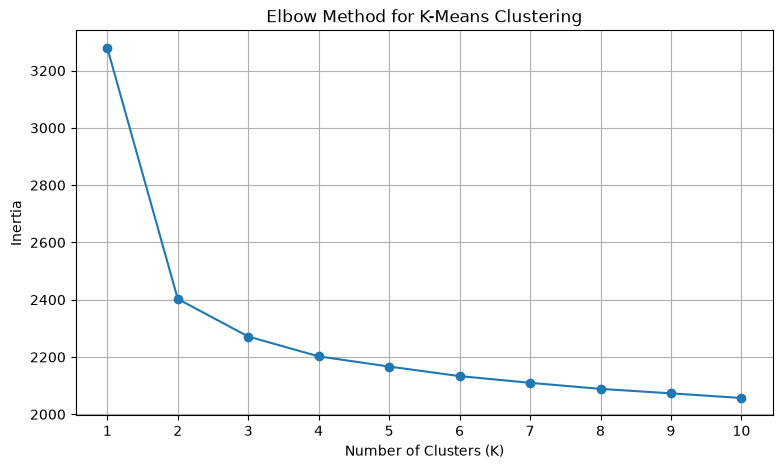

In [3]:

# Step 5: Find the Optimal Number of Clusters

# Import required libraries
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Define the cluster numbers to test
cluster_range = range(1, 11)

# Store inertia values for each cluster number
inertia_values = []

# Train K-Means models with different cluster numbers
for k in cluster_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X)

    # Save the inertia value
    inertia_values.append(kmeans.inertia_)

# Plot the Elbow Method graph
plt.figure(figsize=(9, 5))
plt.plot(cluster_range, inertia_values, marker="o")

plt.title("Elbow Method for K-Means Clustering")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(cluster_range))
plt.grid(True)
plt.show()



## Applying K-Means Clustering

Based on the Elbow Method, I selected three clusters as a reasonable starting point.

I will apply K-Means clustering to the 52 normalized weekly sales features.

The goal is to group products with similar weekly sales patterns.


In [4]:

# Step 6: Apply K-Means Clustering

# Create a K-Means model with 3 clusters
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train the model and predict cluster labels
cluster_labels = kmeans_model.fit_predict(X)

# Add cluster labels to the original dataset
df_clustered = df.copy()
df_clustered["Cluster"] = cluster_labels

# Display the number of products in each cluster
print("Products per Cluster:")
print(df_clustered["Cluster"].value_counts().sort_index())

# Display the first ten products and their clusters
display(df_clustered[["Product_Code", "Cluster"]].head(10))

# Display the model inertia
print("\nModel Inertia:", round(kmeans_model.inertia_, 2))


Products per Cluster:
Cluster
0    263
1    275
2    273
Name: count, dtype: int64


,Product_Code,Cluster
0,P1,2
1,P2,2
2,P3,2
3,P4,0
4,P5,0
5,P6,0
6,P7,2
7,P8,2
8,P9,2
9,P10,2



Model Inertia: 2271.57



## Cluster Analysis and Visualization

The K-Means model divided 811 products into three clusters.

Cluster 0 contains 263 products, Cluster 1 contains 275 products, and Cluster 2 contains 273 products.

I will compare the average normalized weekly sales patterns of these clusters to understand their differences.


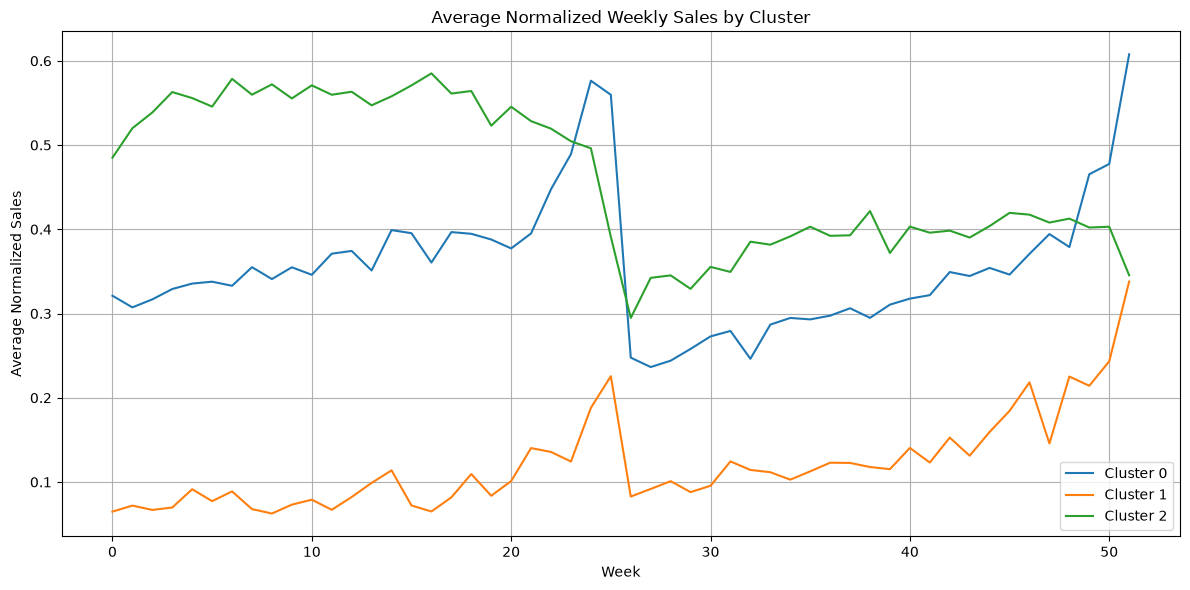

In [5]:

# Step 7: Visualize Average Weekly Sales by Cluster

# Calculate the average normalized sales for each cluster
cluster_averages = df_clustered.groupby("Cluster")[normalized_columns].mean()

# Create a line chart
plt.figure(figsize=(12, 6))

# Plot average weekly sales for each cluster
for cluster_id in cluster_averages.index:
    plt.plot(
        range(52),
        cluster_averages.loc[cluster_id],
        label=f"Cluster {cluster_id}"
    )

# Add chart title and labels
plt.title("Average Normalized Weekly Sales by Cluster")
plt.xlabel("Week")
plt.ylabel("Average Normalized Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()

# Display the chart
plt.show()


In [6]:

# Step 7: Analyze Cluster Sizes

# Count products in each cluster
cluster_counts = df_clustered["Cluster"].value_counts().sort_index()

# Display the number of products per cluster
print("Number of Products in Each Cluster:")
print(cluster_counts)

# Calculate the percentage of products in each cluster
cluster_percentages = (
    cluster_counts / len(df_clustered) * 100
).round(2)

print("\nPercentage of Products in Each Cluster:")
print(cluster_percentages)

# Verify the total number of products
print("\nTotal Products:", cluster_counts.sum())


Number of Products in Each Cluster:
Cluster
0    263
1    275
2    273
Name: count, dtype: int64

Percentage of Products in Each Cluster:
Cluster
0    32.43
1    33.91
2    33.66
Name: count, dtype: float64

Total Products: 811



## Comparing Actual Sales Across Clusters

The K-Means algorithm divided 811 products into three clusters.

I will now compare the actual sales values across the clusters. This will help me understand whether the clusters differ in their average weekly sales and total annual sales.

The clustering was performed using normalized sales data, but this analysis uses the original sales values.


In [7]:

# Step 8: Compare Actual Sales Across Clusters

# Select the original 52 weekly sales columns
weekly_columns = [f"W{i}" for i in range(52)]

# Calculate total annual sales for each product
df_clustered["Annual_Sales"] = df_clustered[weekly_columns].sum(axis=1)

# Calculate average weekly sales for each product
df_clustered["Average_Weekly_Sales"] = df_clustered[weekly_columns].mean(axis=1)

# Summarize actual sales by cluster
cluster_summary = df_clustered.groupby("Cluster").agg(
    Products=("Product_Code", "count"),
    Average_Weekly_Sales=("Average_Weekly_Sales", "mean"),
    Average_Annual_Sales=("Annual_Sales", "mean"),
    Total_Annual_Sales=("Annual_Sales", "sum")
)

# Display the cluster summary
display(cluster_summary.round(2))


,Products,Average_Weekly_Sales,Average_Annual_Sales,Total_Annual_Sales
Cluster,,,,
0,263,6.68,347.51,91396
1,275,0.38,19.65,5404
2,273,19.62,1020.10,278487



## Results and Discussion

The K-Means algorithm divided 811 products into three clusters based on their normalized weekly sales patterns.

### Cluster 0: Moderate Sales

Cluster 0 contains 263 products (32.43%).

The average weekly sales per product were 6.68 units, and the total annual sales were 91,396 units.

This cluster represents products with moderate sales volume.

### Cluster 1: Low Sales

Cluster 1 contains 275 products (33.91%).

The average weekly sales per product were 0.38 units, and the total annual sales were 5,404 units.

This cluster represents products with low sales volume.

### Cluster 2: High Sales

Cluster 2 contains 273 products (33.66%).

The average weekly sales per product were 19.62 units, and the total annual sales were 278,487 units.

This cluster represents products with high sales volume.

## Conclusion

In this assignment, I used Python, pandas, and the K-Means clustering algorithm to analyze weekly sales data for 811 products.

I used the Elbow Method to explore the number of clusters and selected three clusters for the analysis.

The results showed three groups with different sales patterns and sales volumes.

Cluster 2 had the highest sales volume, Cluster 0 had moderate sales, and Cluster 1 had the lowest sales volume.

The analysis demonstrates how unsupervised machine learning can help identify groups of products with similar sales behavior.

However, the clusters were created using normalized weekly sales values, so the sales-volume differences are descriptive findings rather than the direct clustering criteria.
